# Estadísticas globales del Grupo A — 2026

Estadísticas de **toda la zona**, organizadas en dos partes dentro de
`outputs/temporadas/2026/global_grupo_a/liga/`:

- **`temporada/`** — rankings y tendencias de toda la temporada (una sola vez).
- **`fechas/fecha_01 … fecha_36/`** — el **mejor 11 (con banco de 10)** de cada fecha,
  cada uno en su carpeta. Las fechas que todavía no se jugaron quedan con la carpeta creada.

In [1]:
import os, sys
%load_ext autoreload
%autoreload 2
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd(); sys.path.insert(0, PROJECT_ROOT)
import config
from src.analysis import liga
from src.visualization import liga as vliga
from IPython.display import Image, display
def show(p):
    if p and os.path.exists(p): display(Image(filename=p))

## 1. Configuración

In [2]:
SEASON  = '2026'
ROUNDS  = range(1, 37)      # fechas a procesar (se crean las 36 carpetas)
VER_FECHA = 20              # fecha cuyo mejor 11 querés ver acá abajo
TEMP_DIR = config.group_season_stats_dir(SEASON); os.makedirs(TEMP_DIR, exist_ok=True)
print('Temporada ->', TEMP_DIR)
print('Fechas    ->', config.group_league_dir(SEASON) + r'\fechas\fecha_NN')

Temporada -> C:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\global_grupo_a\liga\temporada
Fechas    -> C:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\global_grupo_a\liga\fechas\fecha_NN


## 2. Temporada: tabla resumen + rankings ofensivo/defensivo

,equipo,pj,V,E,D,pts,gf,gc,xgf_pp,xgc_pp
0,Club Ferro Carril Oeste,19,11,4,4,37,22,14,1.41,0.66
1,Gimnasia Jujuy,18,10,5,3,35,30,18,1.44,1.29
2,Deportivo Morón,18,10,3,5,33,26,16,1.23,0.87
3,Los Andes,20,8,8,4,32,19,8,1.12,0.99
4,Club Atlético Colón,19,8,8,3,32,23,15,1.20,0.74
5,Ciudad de Bolívar,20,7,9,4,30,19,16,0.85,1.29
6,Estudiantes de Buenos Aires,19,8,6,5,30,18,15,1.22,0.96
7,Almirante Brown,20,8,6,6,30,15,13,0.98,1.02
8,Godoy Cruz,20,7,7,6,28,20,17,1.32,0.80
9,Deportivo Madryn,18,7,6,5,27,24,19,0.99,1.10


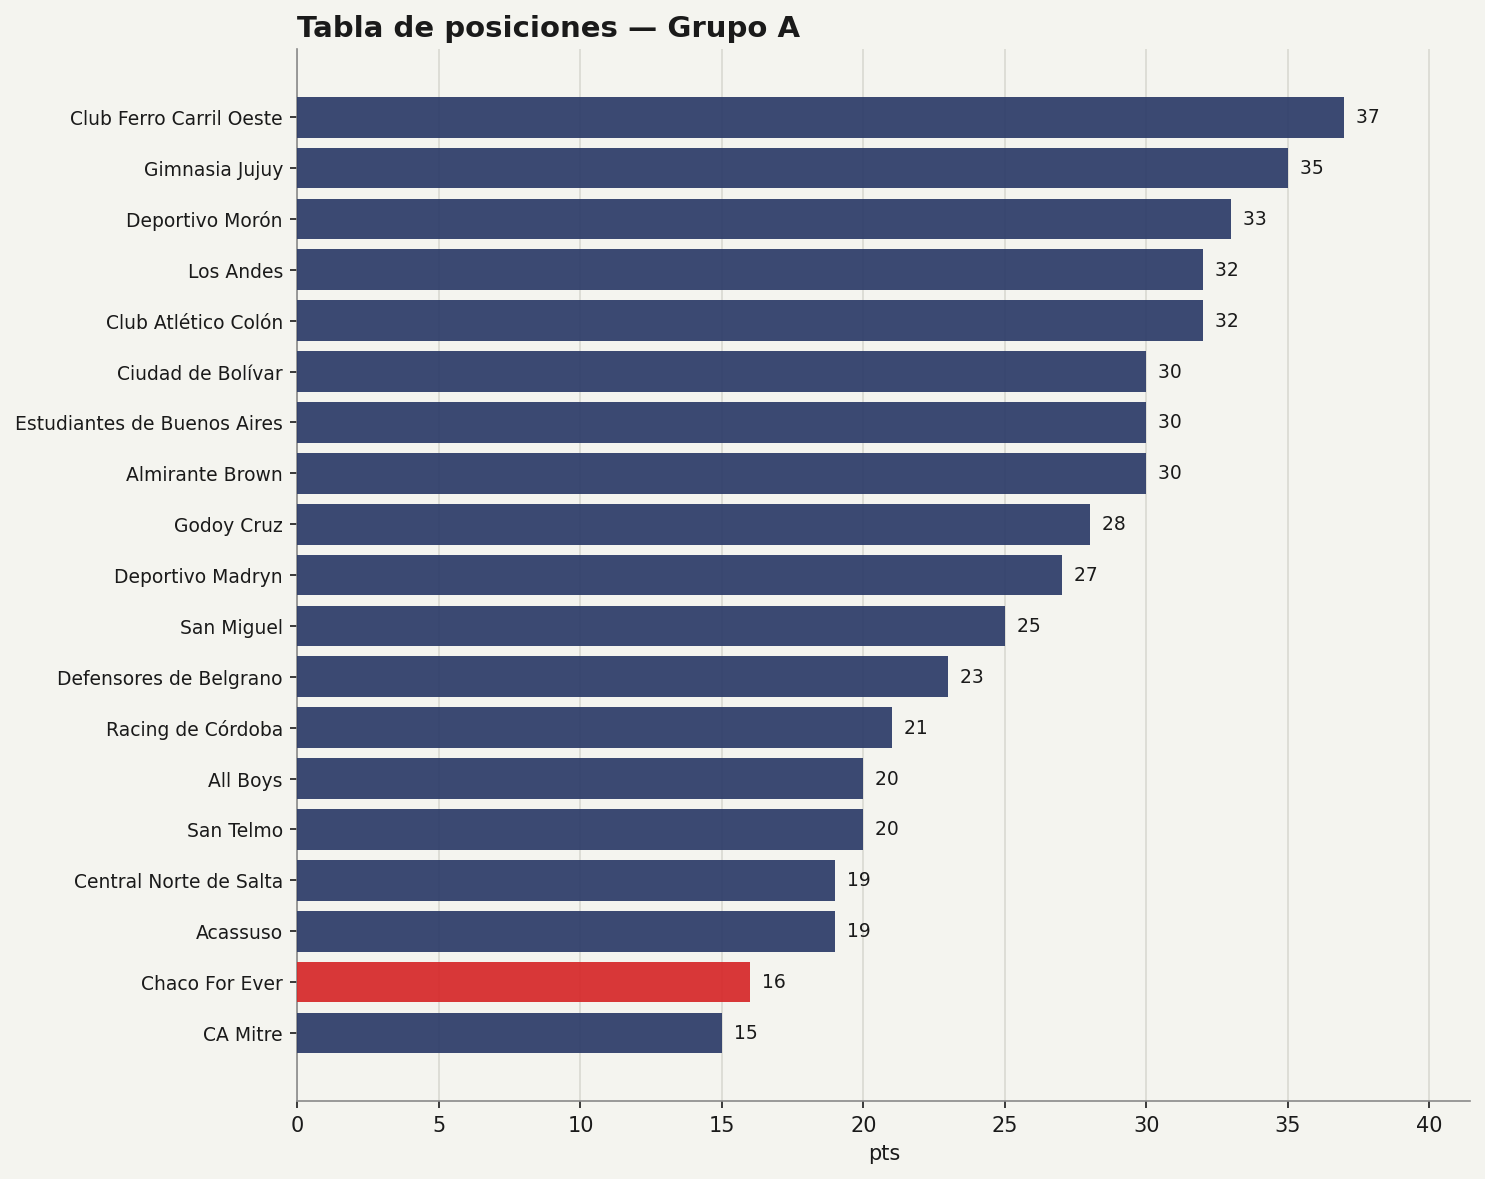

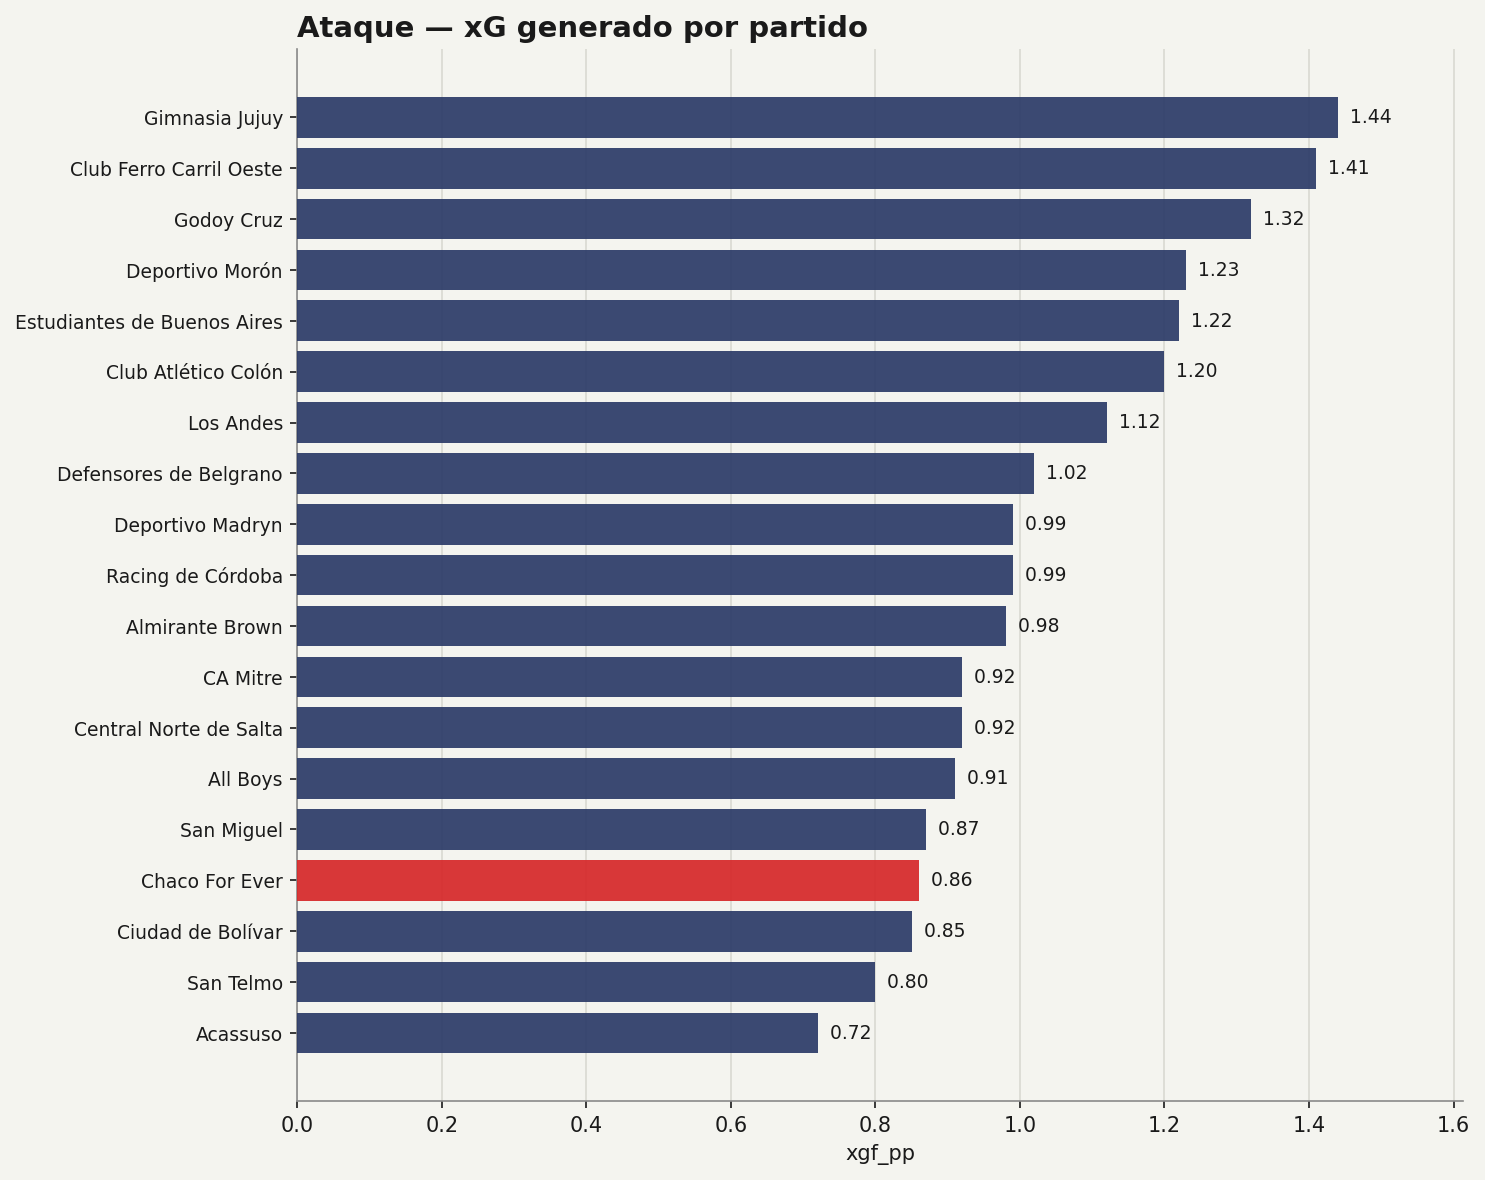

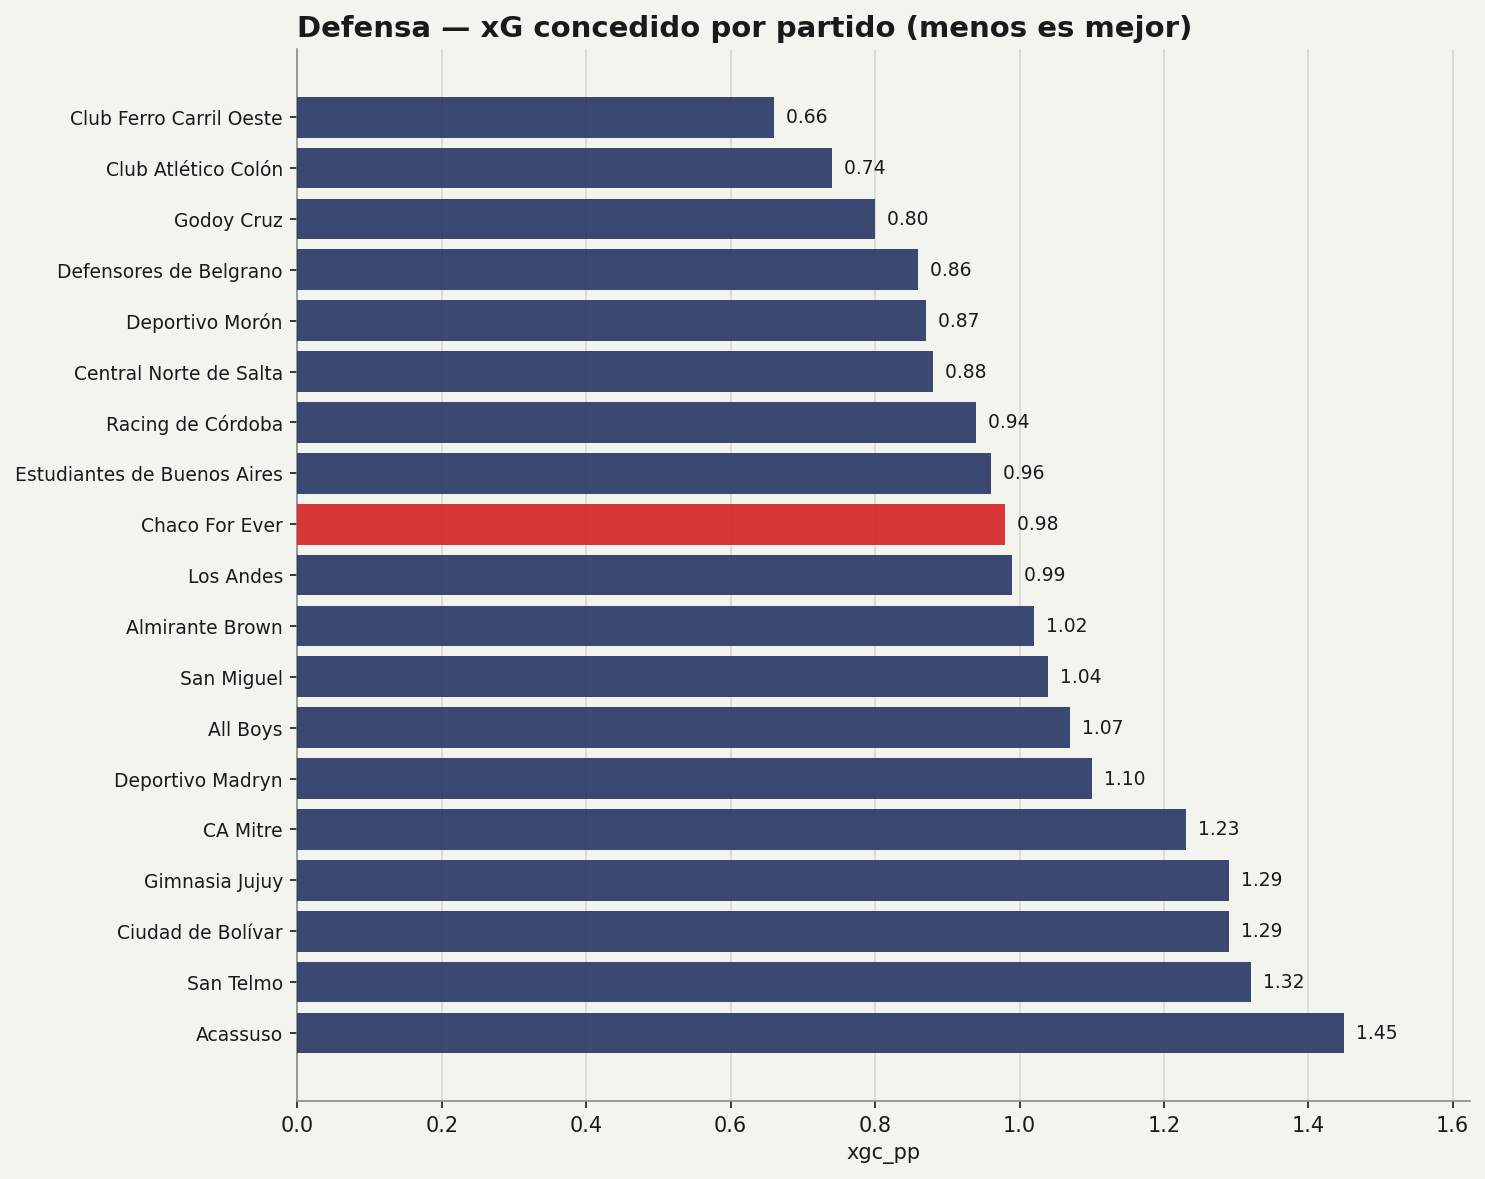

In [3]:
tsum = liga.team_summary_table(SEASON)
tsum.to_csv(os.path.join(TEMP_DIR, 'tabla_resumen_grupo_a.csv'), index=False)
display(tsum[['equipo','pj','V','E','D','pts','gf','gc','xgf_pp','xgc_pp']])

vliga.plot_ranking_bars(tsum, 'pts', title='Tabla de posiciones — Grupo A',
                        fmt='{:.0f}', save_path=os.path.join(TEMP_DIR, 'ranking_puntos.png'))
vliga.plot_ranking_bars(tsum, 'xgf_pp', title='Ataque — xG generado por partido',
                        save_path=os.path.join(TEMP_DIR, 'ranking_ofensivo.png'))
vliga.plot_ranking_bars(tsum, 'xgc_pp', ascending=True,
                        title='Defensa — xG concedido por partido (menos es mejor)',
                        save_path=os.path.join(TEMP_DIR, 'ranking_defensivo.png'))
for f in ['ranking_puntos.png','ranking_ofensivo.png','ranking_defensivo.png']:
    show(os.path.join(TEMP_DIR, f))

## 3. Mejor 11 de CADA fecha (1–36) con banco de 10\nCrea las 36 carpetas y genera el gráfico en las que ya tienen datos.

  fecha  1: ✔ (11 titulares, 10 suplentes)


  fecha  2: ✔ (11 titulares, 10 suplentes)


  fecha  3: ✔ (11 titulares, 10 suplentes)


  fecha  4: ✔ (11 titulares, 10 suplentes)


  fecha  5: ✔ (11 titulares, 10 suplentes)


...

  fecha 32: sin datos aún


  fecha 33: sin datos aún


  fecha 34: sin datos aún


  fecha 35: sin datos aún


  fecha 36: sin datos aún

Fechas con mejor 11 generado: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]

Mostrando fecha 20


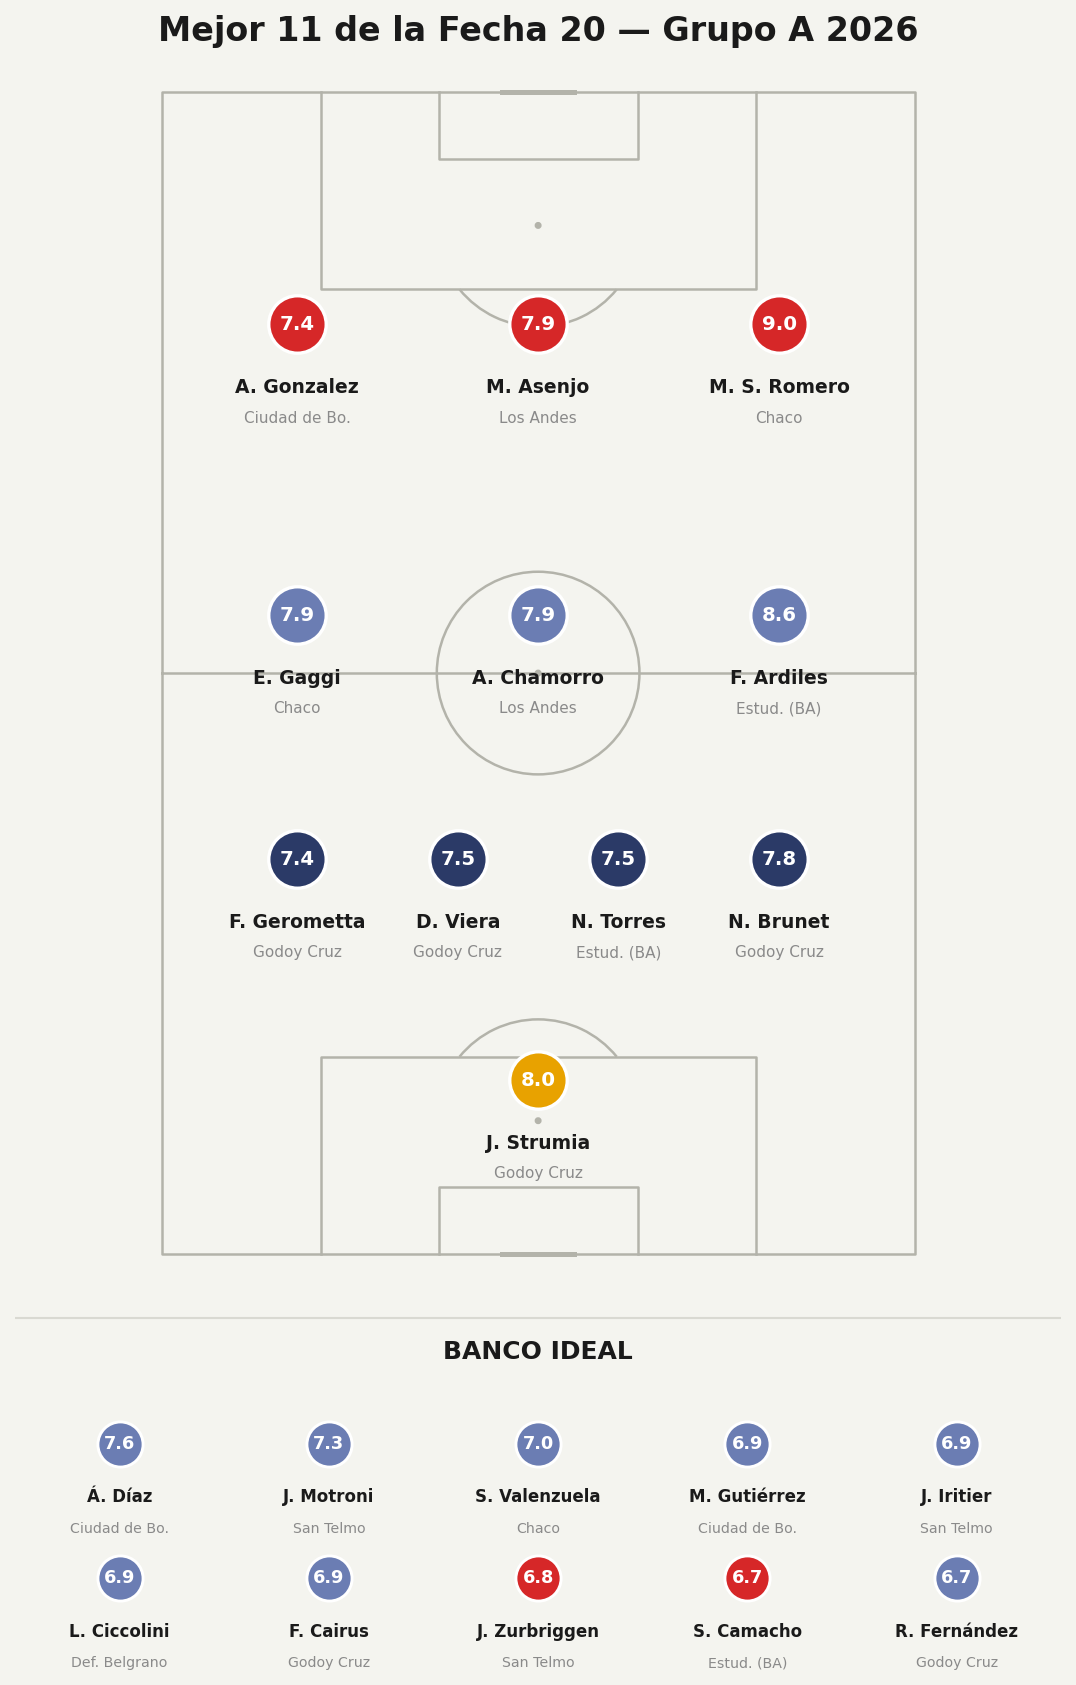

In [4]:
hechas = liga.generate_all_rounds(SEASON, rounds=ROUNDS, verbose=True)

# Ver una fecha puntual:
p = os.path.join(config.group_round_dir(VER_FECHA, SEASON), 'mejor_11.png')
print('\nMostrando fecha', VER_FECHA)
show(p)

## 4. ¿Se juega por el medio? — origen de los remates (temporada)

,equipo,zona,n,pct
0,LIGA,area_centro,1552,39.4
1,LIGA,area_lateral,602,15.3
2,LIGA,fuera_centro,1065,27.0
3,LIGA,fuera_lateral,723,18.3


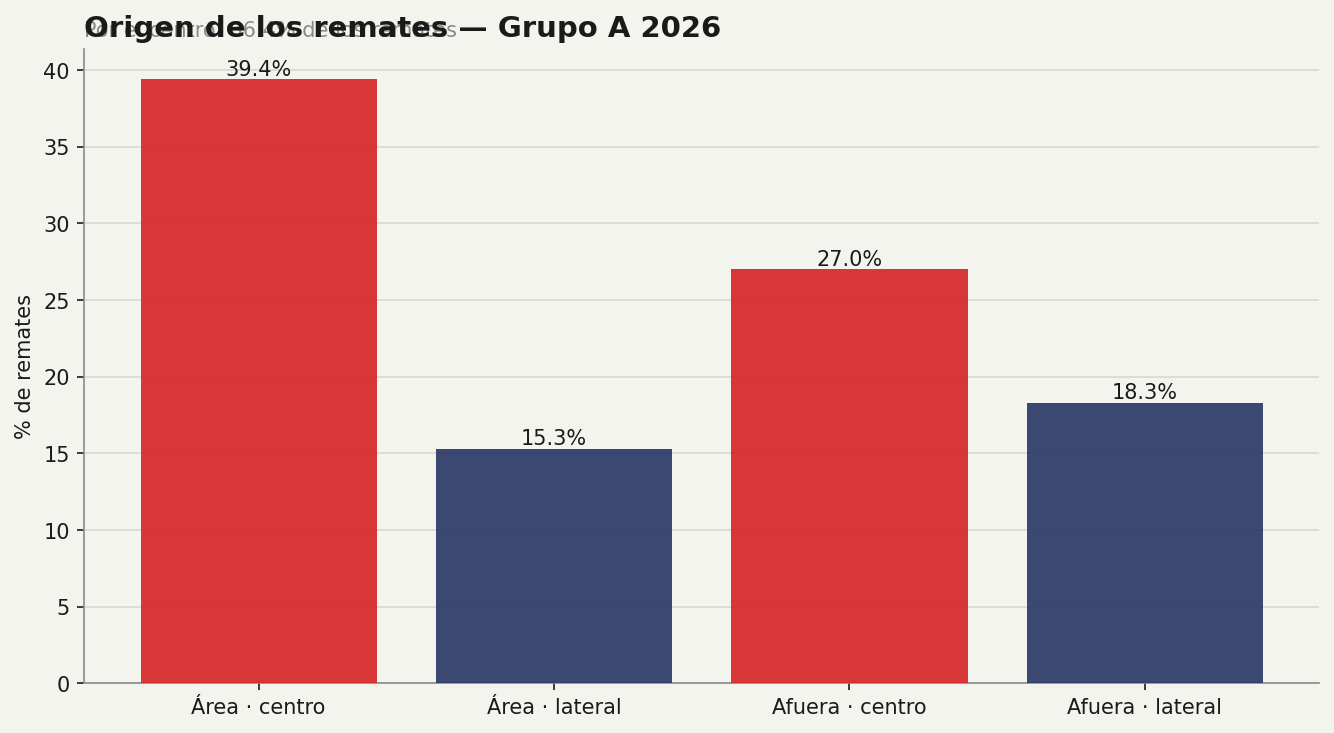


De la temporada: 66.4% de los remates del grupo nacen por el corredor central.


In [5]:
so = liga.shot_origin_distribution(SEASON, by_team=False)
so.to_csv(os.path.join(TEMP_DIR, 'origen_remates_liga.csv'), index=False)
display(so)
p = os.path.join(TEMP_DIR, 'origen_remates.png')
vliga.plot_shot_origin(so, season=SEASON, save_path=p)
show(p)
central = round(so[so.zona.str.endswith('centro')]['n'].sum() / so['n'].sum() * 100, 1)
print(f'\nDe la temporada: {central}% de los remates del grupo nacen por el corredor central.')

## Notas
- Para ver otra fecha: cambiá `VER_FECHA`. Todas quedan guardadas en `liga/fechas/fecha_NN/`
  (`mejor_11.png` + `mejor_11.csv` + `banco.csv`).
- Al cerrar cada fecha nueva, volvé a correr la sección 3: genera solo lo que falte.
- `liga.shot_origin_distribution(SEASON, by_team=True)` desglosa el origen por equipo.